In [59]:
from pathlib import Path
import json

root = Path(r"C:\Users\m\Downloads\TACO-master")
annotations_path = root / "data" / "annotations.json"

print("Project folder exists:", root.exists())
print("Annotations file exists:", annotations_path.exists())
print("Batch folders:", sorted(
    p.name for p in (root / "data").glob("batch_*") if p.is_dir()
))

Project folder exists: True
Annotations file exists: True
Batch folders: ['batch_1', 'batch_10', 'batch_11', 'batch_12', 'batch_13', 'batch_14', 'batch_15', 'batch_2', 'batch_3', 'batch_4', 'batch_5', 'batch_6', 'batch_7', 'batch_8', 'batch_9']


In [60]:

from pathlib import Path
import json

root = Path(r"C:\Users\m\Downloads\TACO-master")
data_dir = root / "data"

with open(data_dir / "annotations.json", "r", encoding="utf-8") as f:
    data = json.load(f)

images = data["images"]
found = []
missing = []

for image in images:
    path = data_dir / image["file_name"]
    if path.is_file():
        found.append(path)
    else:
        missing.append(image["file_name"])

print("Images listed in JSON:", len(images))
print("Images found on disk:", len(found))
print("Images missing:", len(missing))

if missing:
    print("\nFirst missing paths:")
    for name in missing[:10]:
        print(name)


Images listed in JSON: 1500
Images found on disk: 1500
Images missing: 0


In [61]:

from collections import defaultdict
from hashlib import sha256

hash_to_files = defaultdict(list)

for image_path in found:
    try:
        with open(image_path, "rb") as f:
            digest = sha256(f.read()).hexdigest()
        hash_to_files[digest].append(str(image_path))
    except OSError as e:
        print("Could not read:", image_path, "|", e)

duplicate_groups = [
    files for files in hash_to_files.values()
    if len(files) > 1
]

duplicate_images = sum(len(files) - 1 for files in duplicate_groups)

print("Images hashed:", sum(len(v) for v in hash_to_files.values()))
print("Exact duplicate groups:", len(duplicate_groups))
print("Extra duplicate copies:", duplicate_images)

for i, group in enumerate(duplicate_groups[:10], start=1):
    print(f"\nDuplicate group {i}:")
    for filename in group:
        print(" ", filename)


Images hashed: 1500
Exact duplicate groups: 0
Extra duplicate copies: 0


In [62]:

from collections import defaultdict
from hashlib import sha256

hash_to_files = defaultdict(list)

for image_path in found:
    try:
        with open(image_path, "rb") as f:
            digest = sha256(f.read()).hexdigest()
        hash_to_files[digest].append(str(image_path))
    except OSError as e:
        print("Could not read:", image_path, "|", e)

duplicate_groups = [
    files for files in hash_to_files.values()
    if len(files) > 1
]

duplicate_images = sum(len(files) - 1 for files in duplicate_groups)

print("Images hashed:", sum(len(v) for v in hash_to_files.values()))
print("Exact duplicate groups:", len(duplicate_groups))
print("Extra duplicate copies:", duplicate_images)

for i, group in enumerate(duplicate_groups[:10], start=1):
    print(f"\nDuplicate group {i}:")
    for filename in group:
        print(" ", filename)


Images hashed: 1500
Exact duplicate groups: 0
Extra duplicate copies: 0


In [63]:

import pandas as pd
from collections import Counter

categories = {c["id"]: c["name"] for c in data["categories"]}
annotations_df = pd.DataFrame(data["annotations"])
images_df = pd.DataFrame(data["images"])

# Check annotation integrity
valid_image_ids = {img["id"] for img in data["images"]}
valid_category_ids = set(categories)

missing_image_refs = (~annotations_df["image_id"].isin(valid_image_ids)).sum()
missing_category_refs = (~annotations_df["category_id"].isin(valid_category_ids)).sum()
missing_bbox = annotations_df["bbox"].isna().sum()

print("Total images:", len(images_df))
print("Total annotations / bounding boxes:", len(annotations_df))
print("TACO categories:", len(categories))
print("Annotations with invalid image reference:", missing_image_refs)
print("Annotations with invalid category reference:", missing_category_refs)
print("Annotations missing bbox:", missing_bbox)

print("\nTop 20 categories by annotation count:")
category_counts = (
    annotations_df["category_id"]
    .map(categories)
    .value_counts()
)
display(category_counts.head(20).to_frame("Annotation count"))


Total images: 1500
Total annotations / bounding boxes: 4784
TACO categories: 60
Annotations with invalid image reference: 0
Annotations with invalid category reference: 0
Annotations missing bbox: 0

Top 20 categories by annotation count:


,Annotation count
category_id,
Cigarette,667
Unlabeled litter,517
Plastic film,451
Clear plastic bottle,285
Other plastic,273
Other plastic wrapper,260
Drink can,229
Plastic bottle cap,209
Plastic straw,157


In [64]:

%pip install pandas


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [65]:

# Map TACO categories to the 5 CleanOps core classes

def map_to_cleanops(category_name):
    name = category_name.lower()

    # Plastic
    if any(word in name for word in [
        "plastic", "polypropylene", "styrofoam",
        "foam", "polystyrene", "six pack rings"
    ]):
        return "Plastic"

    # Paper / Cardboard
    if any(word in name for word in [
        "paper", "carton", "cardboard", "magazine",
        "tissue", "pizza box", "egg carton"
    ]):
        return "Paper/Cardboard"

    # Glass
    if "glass" in name:
        return "Glass"

    # Metal
    if any(word in name for word in [
        "metal", "aluminium", "aluminum", "can",
        "aerosol", "battery", "pop tab"
    ]):
        return "Metal"

    # Organic / Trash
    return "Organic/Trash"


# Add the CleanOps class to every annotation
annotations_df["category_name"] = (
    annotations_df["category_id"].map(categories)
)

annotations_df["cleanops_class"] = (
    annotations_df["category_name"].apply(map_to_cleanops)
)

# Count bounding boxes per CleanOps class
class_counts = (
    annotations_df["cleanops_class"]
    .value_counts()
    .reindex(
        ["Plastic", "Paper/Cardboard", "Glass", "Metal", "Organic/Trash"],
        fill_value=0
    )
)

print("CleanOps Core Class Distribution")
display(class_counts.to_frame("Bounding Box Count"))

print("\nTotal mapped annotations:", class_counts.sum())
print("Original annotation count:", len(annotations_df))


CleanOps Core Class Distribution


,Bounding Box Count
cleanops_class,
Plastic,2063
Paper/Cardboard,492
Glass,254
Metal,552
Organic/Trash,1423



Total mapped annotations: 4784
Original annotation count: 4784


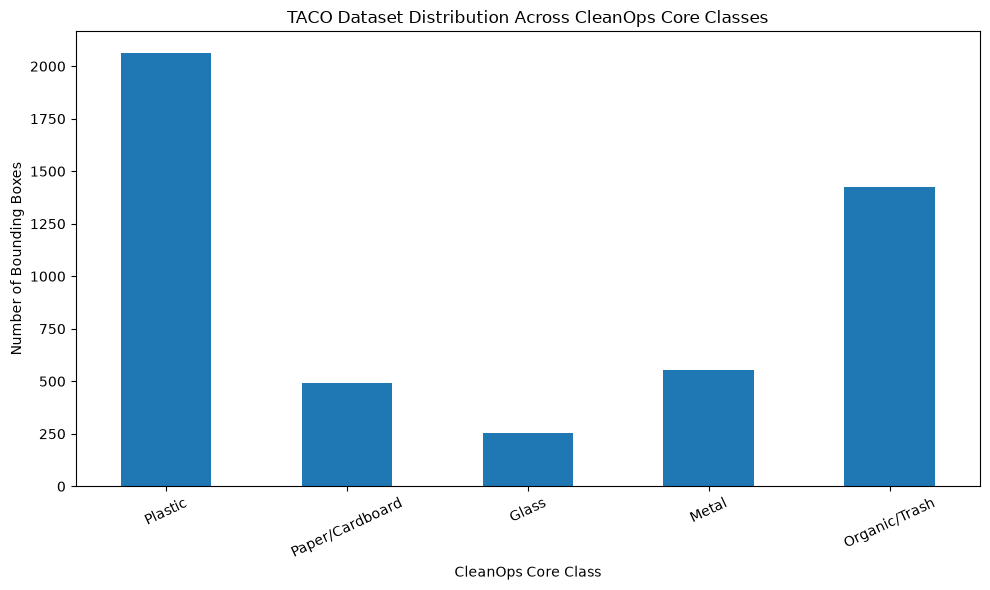

Chart saved successfully.


In [66]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

class_counts.plot(
    kind="bar",
    rot=25
)

plt.title("TACO Dataset Distribution Across CleanOps Core Classes")
plt.xlabel("CleanOps Core Class")
plt.ylabel("Number of Bounding Boxes")
plt.tight_layout()

plt.savefig(
    "waste_categories_barchart.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully.")


In [67]:

%pip install matplotlib


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [68]:

# Calculate class percentages
class_summary = class_counts.rename_axis("CleanOps Class").to_frame(
    "Bounding Box Count"
)

class_summary["Percentage (%)"] = (
    class_summary["Bounding Box Count"] / len(annotations_df) * 100
).round(2)

print("CleanOps Class Summary")
display(class_summary)

# Review categories that may need manual mapping verification
print("\nCategories requiring mapping review:")

review_keywords = [
    "unlabeled", "litter", "drink can", "food waste",
    "shoe", "cigarette", "rope", "battery"
]

review_categories = sorted([
    name for name in categories.values()
    if any(keyword in name.lower() for keyword in review_keywords)
])

for name in review_categories:
    count = (annotations_df["category_name"] == name).sum()
    mapped_class = map_to_cleanops(name)
    print(f"{name}: {count} annotations -> {mapped_class}")


CleanOps Class Summary


,Bounding Box Count,Percentage (%)
CleanOps Class,,
Plastic,2063,43.12
Paper/Cardboard,492,10.28
Glass,254,5.31
Metal,552,11.54
Organic/Trash,1423,29.74



Categories requiring mapping review:
Battery: 2 annotations -> Metal
Cigarette: 667 annotations -> Organic/Trash
Drink can: 229 annotations -> Metal
Food waste: 8 annotations -> Organic/Trash
Rope & strings: 29 annotations -> Organic/Trash
Shoe: 7 annotations -> Organic/Trash
Unlabeled litter: 517 annotations -> Organic/Trash


In [69]:

from pathlib import Path
from datetime import date

# Set project folders
project_root = Path(r"C:\Users\m\Downloads\TACO-master")
analytics_dir = project_root / "docs" / "analytics"
figures_dir = analytics_dir / "figures"

analytics_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# Save the chart in the required location
chart_path = figures_dir / "waste_categories_barchart.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")

# Build class distribution table
class_table = "\n".join(
    f"| {name} | {int(count)} | {count / len(annotations_df) * 100:.2f}% |"
    for name, count in class_counts.items()
)

# Build top 20 original categories table
top_categories = annotations_df["category_name"].value_counts().head(20)
top_table = "\n".join(
    f"| {name} | {int(count)} |"
    for name, count in top_categories.items()
)

report = f"""# CleanOps Waste Dataset Analysis Report

## 1. Objective
Audit the TACO waste dataset, assess annotation integrity,
summarize category distribution, and map the original categories
to the five CleanOps core classes.

## 2. Dataset Overview
- Total images listed in annotations: {len(images_df)}
- Total annotations / bounding boxes: {len(annotations_df)}
- Original TACO categories: {len(categories)}
- Images found on disk: 1500
- Missing images: 0
- Exact duplicate image groups detected by SHA-256: 0
- Invalid image references: {int(missing_image_refs)}
- Invalid category references: {int(missing_category_refs)}
- Annotations missing bounding boxes: {int(missing_bbox)}

## 3. CleanOps Core Class Distribution

| CleanOps Class | Bounding Box Count | Percentage |
|---|---:|---:|
{class_table}
| **Total** | **{int(class_counts.sum())}** | **100.00% (rounded)** |

Percentages are calculated using the total annotation count.
Individual rounded percentages may not sum to exactly 100%.

![CleanOps core class distribution](figures/waste_categories_barchart.png)

## 4. Top 20 Original Categories

| TACO Category | Annotation Count |
|---|---:|
{top_table}

## 5. Duplicate and Augmentation Checks
All {len(images_df)} image files were found on disk.
A SHA-256 exact-file comparison found no exact duplicate groups.
This check does not detect visually similar images, resized or
re-encoded copies, or augmented versions. Those require a separate
perceptual-image comparison and review.

## 6. Mapping Method and Limitations
The 60 original TACO categories were assigned to five CleanOps
classes using name-based keyword rules. The mapping is a preliminary
rule-based mapping, not a verified material classification model.

Categories such as Cigarette, Unlabeled litter, Shoe, Rope & strings,
and Food waste were assigned to Organic/Trash by the current fallback
rule. These assignments should be reviewed and documented with the
project team before the mapping is treated as final.

## 7. Data Quality Findings
- All listed images were found on disk.
- All annotations reference valid image and category IDs.
- No annotations were missing bounding boxes.
- Exact duplicate groups were not detected by SHA-256.

## 8. Recommendations
1. Review and approve the mapping rules with the CleanOps team.
2. Decide how ambiguous or mixed-material items should be classified.
3. Run a perceptual similarity check to investigate near-duplicates.
4. Inspect image samples from each core class to validate the mapping.
5. Keep the original TACO category alongside the mapped CleanOps class
   to preserve traceability.

## 9. Reproducibility
The analysis should be reproducible by running all notebook cells
in order with the TACO annotations and image batches available.
"""

report_path = analytics_dir / "dataset_analysis_report.md"
report_path.write_text(report, encoding="utf-8")

print("Report saved:", report_path)
print("Report exists:", report_path.exists())
print("Chart saved:", chart_path)
print("Chart exists:", chart_path.exists())


Report saved: C:\Users\m\Downloads\TACO-master\docs\analytics\dataset_analysis_report.md
Report exists: True
Chart saved: C:\Users\m\Downloads\TACO-master\docs\analytics\figures\waste_categories_barchart.png
Chart exists: True


<Figure size 640x480 with 0 Axes>

Chart exists: True
Chart size (bytes): 15139


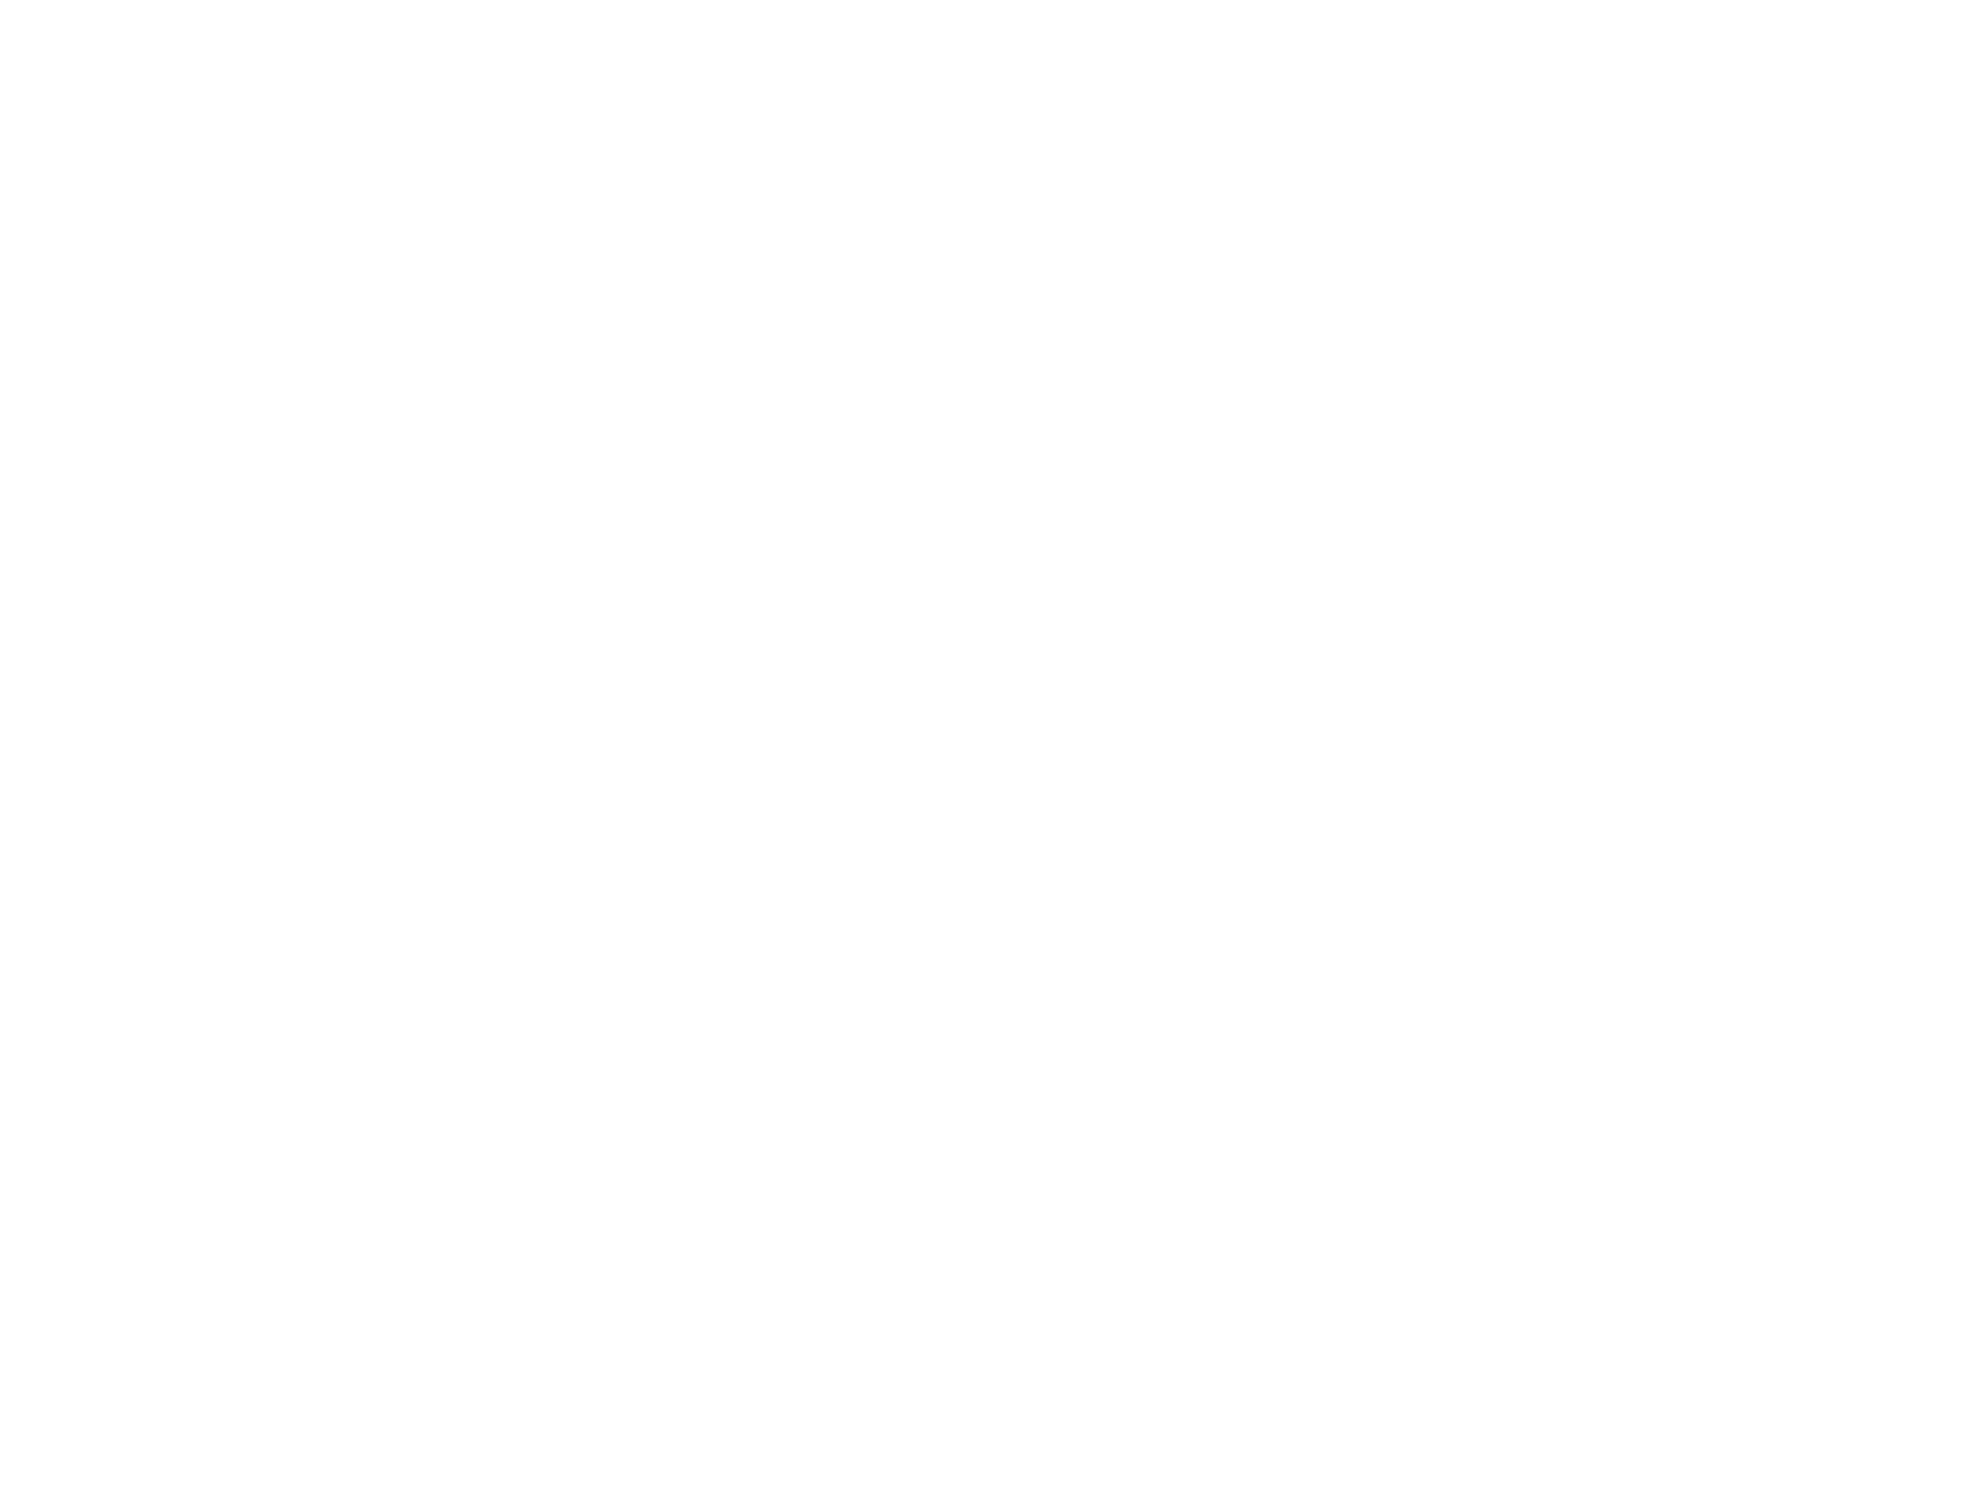

In [70]:

from IPython.display import display, Image
from pathlib import Path

chart_path = Path(
    r"C:\Users\m\Downloads\TACO-master\docs\analytics\figures\waste_categories_barchart.png"
)

print("Chart exists:", chart_path.exists())
print("Chart size (bytes):", chart_path.stat().st_size if chart_path.exists() else 0)

if chart_path.exists():
    display(Image(filename=str(chart_path)))


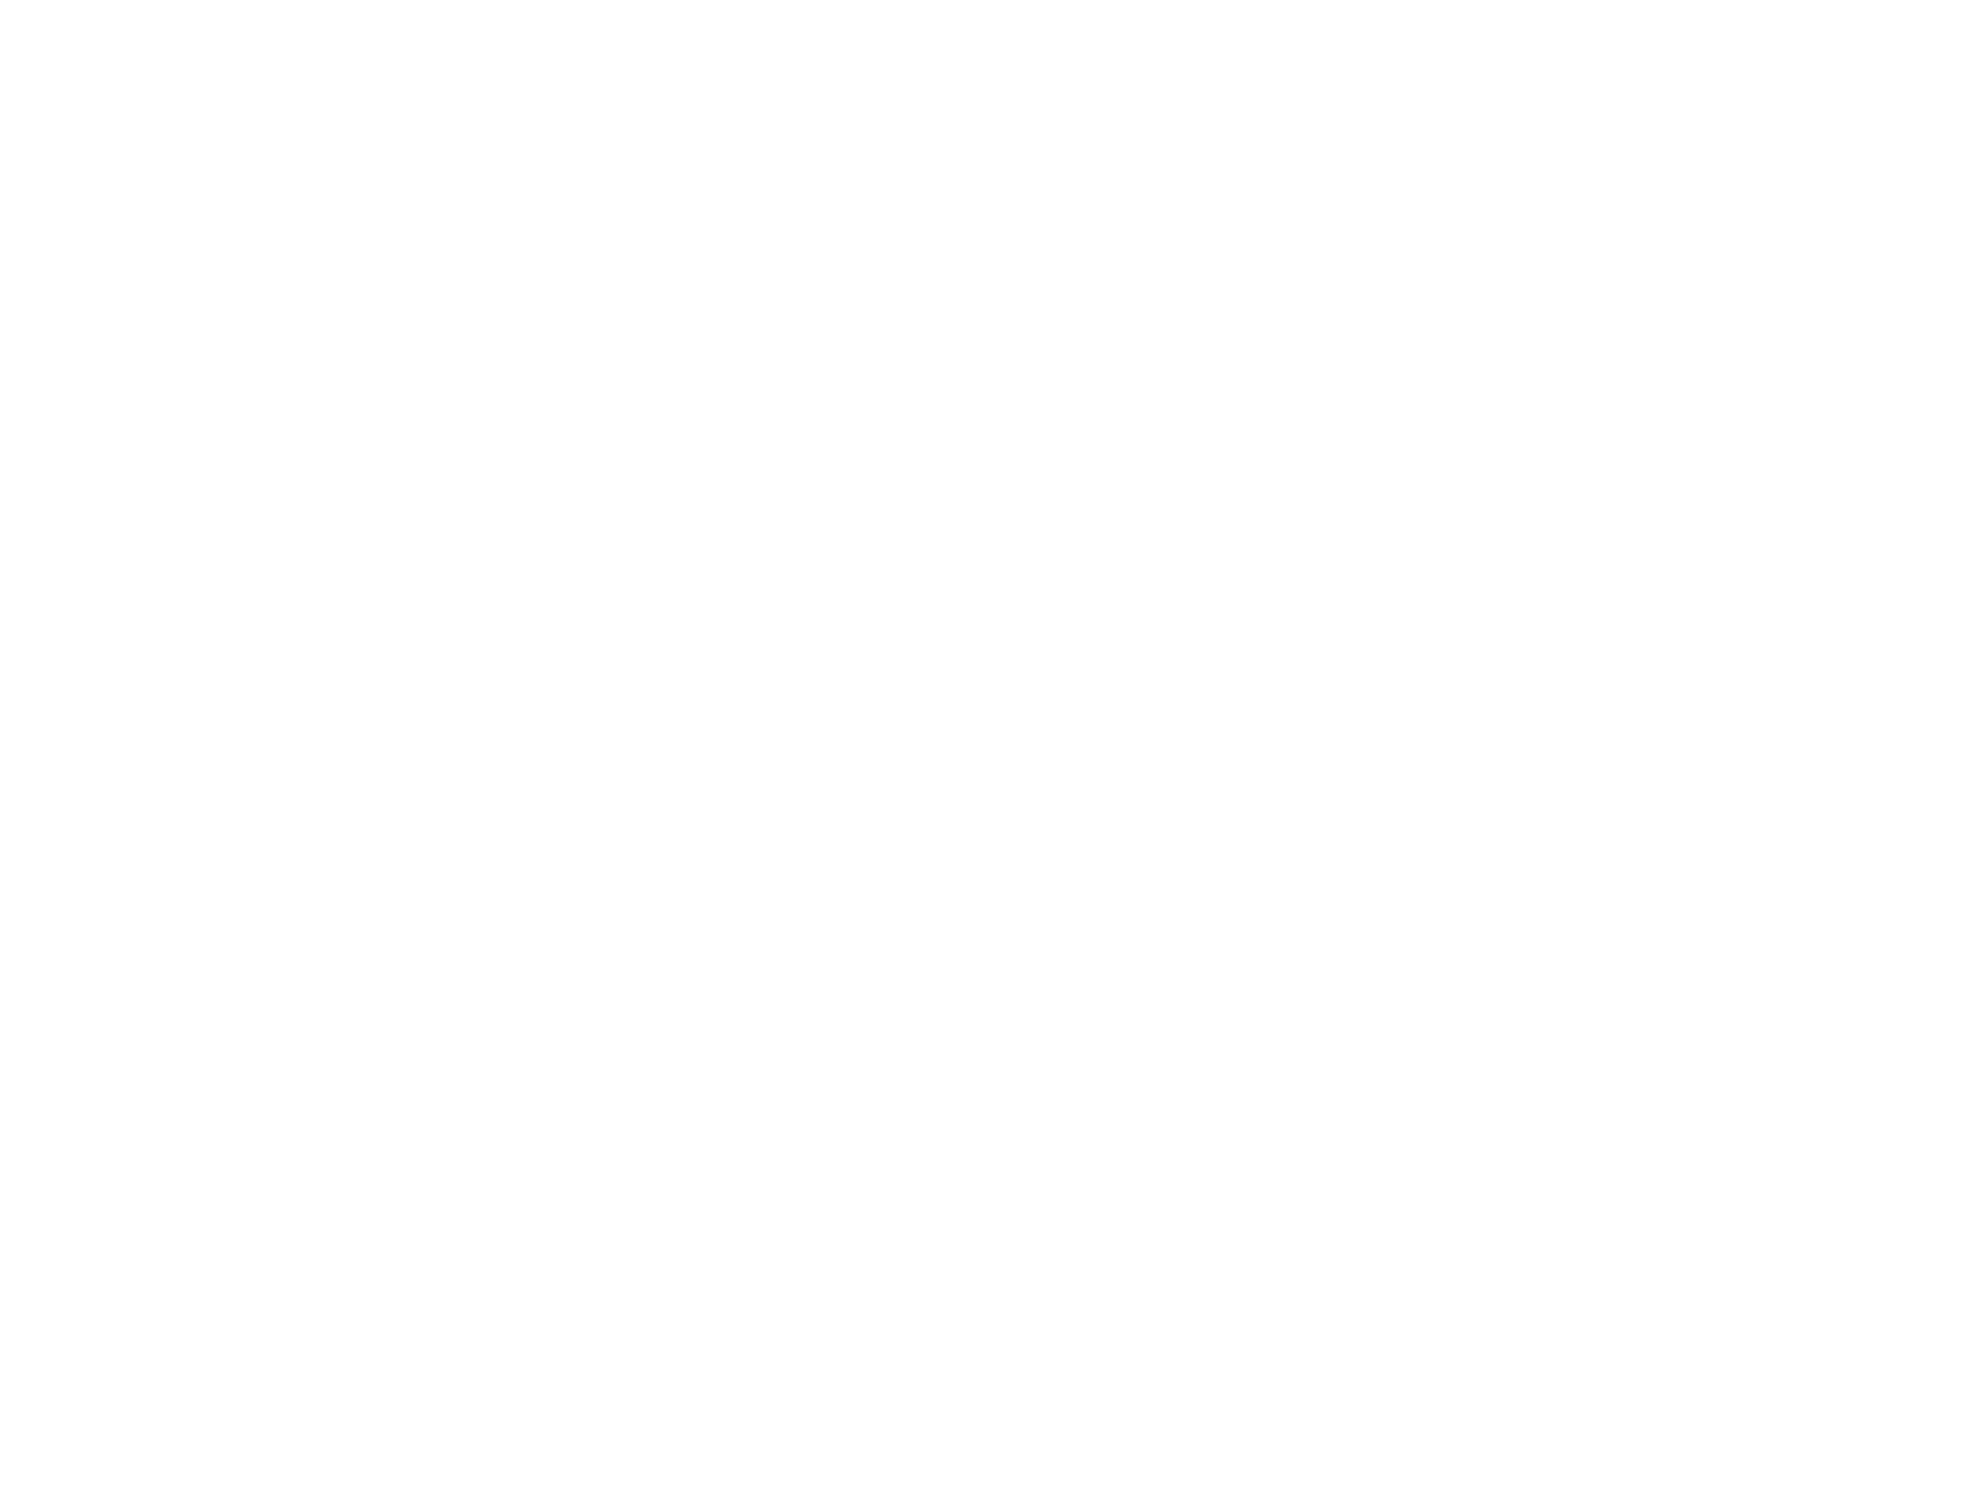

In [71]:
from IPython.display import display, Image
from pathlib import Path

chart_path = Path(
    r"C:\Users\m\Downloads\TACO-master\docs\analytics\figures\waste_categories_barchart.png"
)

display(Image(filename=str(chart_path)))

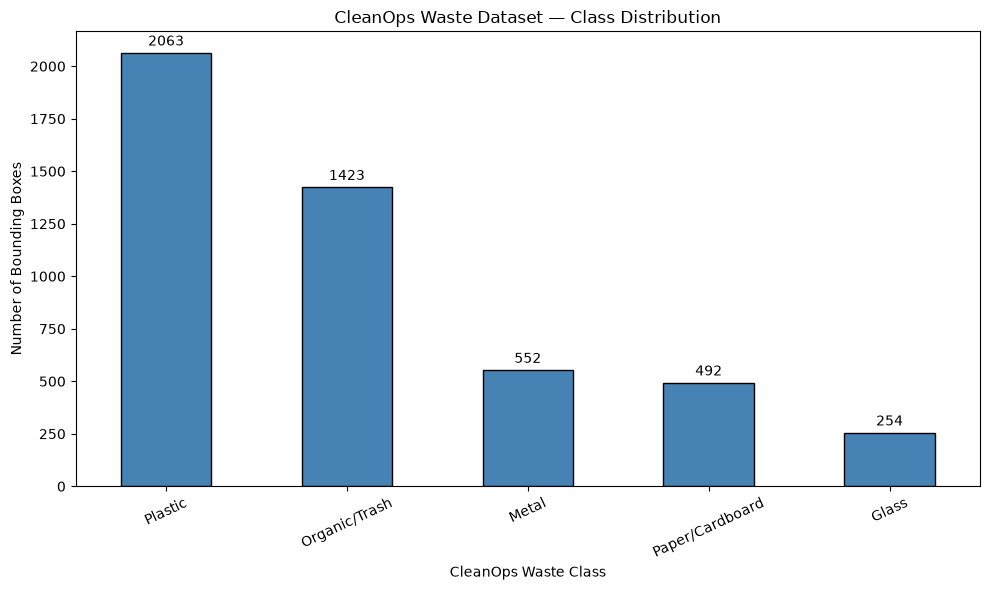

Chart saved successfully: C:\Users\m\Downloads\TACO-master\docs\analytics\figures\waste_categories_barchart.png


In [72]:
import matplotlib.pyplot as plt

# Recalculate the CleanOps class distribution
class_counts = annotations_df["cleanops_class"].value_counts()

# Create a fresh chart
fig, ax = plt.subplots(figsize=(10, 6))

class_counts.plot(
    kind="bar",
    ax=ax,
    color="steelblue",
    edgecolor="black"
)

ax.set_title("CleanOps Waste Dataset — Class Distribution")
ax.set_xlabel("CleanOps Waste Class")
ax.set_ylabel("Number of Bounding Boxes")
ax.tick_params(axis="x", rotation=25)

# Display values above the bars
for container in ax.containers:
    ax.bar_label(container, padding=3)

fig.tight_layout()

# Save the chart
chart_path = (
    r"C:\Users\m\Downloads\TACO-master\docs\analytics"
    r"\figures\waste_categories_barchart.png"
)

fig.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved successfully:", chart_path)

In [73]:
from pathlib import Path

project_root = Path(r"C:\Users\m\Downloads\TACO-master")

required_paths = [
    project_root / "data" / "notebooks" / "cleanops_waste_analysis.ipynb",
    project_root / "docs" / "analytics" / "dataset_analysis_report.md",
    project_root / "docs" / "analytics" / "figures" / "waste_categories_barchart.png",
]

for path in required_paths:
    print(("FOUND ✅ " if path.exists() else "MISSING ❌ "), path)

FOUND ✅  C:\Users\m\Downloads\TACO-master\data\notebooks\cleanops_waste_analysis.ipynb
FOUND ✅  C:\Users\m\Downloads\TACO-master\docs\analytics\dataset_analysis_report.md
FOUND ✅  C:\Users\m\Downloads\TACO-master\docs\analytics\figures\waste_categories_barchart.png


In [74]:
from pathlib import Path

project_root = Path(r"C:\Users\m\Downloads\TACO-master")
notebook_dir = project_root / "data" / "notebooks"
notebook_dir.mkdir(parents=True, exist_ok=True)

print("Notebook folder ready:", notebook_dir)

Notebook folder ready: C:\Users\m\Downloads\TACO-master\data\notebooks


In [75]:
from pathlib import Path

project_root = Path(r"C:\Users\m\Downloads\TACO-master")

for path in [
    project_root / "data" / "notebooks" / "cleanops_waste_analysis.ipynb",
    project_root / "docs" / "analytics" / "dataset_analysis_report.md",
    project_root / "docs" / "analytics" / "figures" / "waste_categories_barchart.png",
]:
    print(("FOUND ✅ " if path.exists() else "MISSING ❌ "), path)

FOUND ✅  C:\Users\m\Downloads\TACO-master\data\notebooks\cleanops_waste_analysis.ipynb
FOUND ✅  C:\Users\m\Downloads\TACO-master\docs\analytics\dataset_analysis_report.md
FOUND ✅  C:\Users\m\Downloads\TACO-master\docs\analytics\figures\waste_categories_barchart.png


In [76]:
from pathlib import Path

project_root = Path(r"C:\Users\m\Downloads\TACO-master")

for path in [
    project_root / "data" / "notebooks" / "cleanops_waste_analysis.ipynb",
    project_root / "docs" / "analytics" / "dataset_analysis_report.md",
    project_root / "docs" / "analytics" / "figures" / "waste_categories_barchart.png",
]:
   print(("FOUND ✅ " if path.exists() else "MISSING ❌ "), path)

FOUND ✅  C:\Users\m\Downloads\TACO-master\data\notebooks\cleanops_waste_analysis.ipynb
FOUND ✅  C:\Users\m\Downloads\TACO-master\docs\analytics\dataset_analysis_report.md
FOUND ✅  C:\Users\m\Downloads\TACO-master\docs\analytics\figures\waste_categories_barchart.png
